In [ ]:
# -*- coding: utf-8 -*-
"""CONTINUOUS EEG PREPROCESSING PIPELINE — PINN Theta Proto

Saves the full continuous preprocessed EEG with event markers
instead of cutting isolated epochs. This preserves temporal
continuity for both expanded-bounds BOB and PINN training.

Changes from the epoch-based pipeline:
  - Continuous EEG saved as (n_ch, n_samples) per subject
  - Onset/offset indices saved as markers, not used for cutting
  - Chronological 60/40 cal/test split computed on events
  - GT computation deferred to model code (depends on split + band)
  - Best theta channel + SNR computed on cal portion only
  - Downsampled copy at 200 Hz saved alongside 600 Hz original

Output per subject:
  continuous_eeg_600hz:  (n_ch, n_samples)     full recording at 600 Hz
  continuous_eeg_200hz:  (n_ch, n_samples_ds)   decimated to 200 Hz
  onset_indices_600hz:   (n_onsets,)            sample indices at 600 Hz
  onset_indices_200hz:   (n_onsets,)            sample indices at 200 Hz
  offset_indices_600hz:  (n_offsets,)
  offset_indices_200hz:  (n_offsets,)
  onset_codes:           (n_onsets,)            stimulus codes
  offset_codes:          (n_offsets,)
  cal_split_event:       int                    first TEST event index
  cal_split_sample_600hz: int                   split sample at 600 Hz
  cal_split_sample_200hz: int                   split sample at 200 Hz
"""

# raise SystemExit("Cell skipped")

import numpy as np
import scipy.io as sio
from scipy.signal import butter, filtfilt, hilbert, welch, decimate
import os, re, json, time, gc

from google.colab import drive
drive.mount('/content/drive')

# ============================================================
# CONFIGURATION
# ============================================================

BASE_DIR = '/content/drive/MyDrive/Rain/RAIN_/Ulnal_median_nerves_stim/Pilot'
OUTPUT_DIR = '/content/drive/MyDrive/PINN_theta_proto'
os.makedirs(OUTPUT_DIR, exist_ok=True)

SUBJECTS = [
    ('Ben_01',      'Ben_Run1_sequence2S001R01.dat'),
    ('Ben_04',      'BenS004R01.dat'),
    ('Ben_05',      'BenS005R01.dat'),
    ('Danting_01',  'DantingS001R01.dat'),
    ('Danting_02',  'DantingS002R02.dat'),
    ('Danting_03',  'DantingS003R01.dat'),
    ('Gansheng_01', 'GanshengS001R01.dat'),
    ('Kara_01',     'KaraS001R02.dat'),
    ('Kara_02',     'KaraS002R02.dat'),
    ('Kara_03',     'KaraS003R01.dat'),
    ('Karan_01',    'KaranS001R02.dat'),
    ('Karan_02',    'KaranS002R01.dat'),
    ('Karan_03',    'KaranS003R01.dat'),
    ('Nabi_01',     'Nabi_Run1S001R01.dat'),
    ('Patrick_01',  'Patrick_RAIN_S2S001R01.dat'),
    ('Patrick_03',  'Patrick_T1S001R01.dat'),
]

EXCLUDE_CH = ['X1', 'X2', 'X3', 'A2', 'TRG']

FS_ORIG = 600.0
FS_DS = 200.0
DECIMATE_FACTOR = int(FS_ORIG / FS_DS)  # 3

# Chronological split: first 60% of onsets = cal, last 40% = test
CAL_FRACTION = 0.60

# Expected stimulation duration (for ISI verification)
EXPECTED_STIM_DURATION_S = 5.0
STIM_DURATION_TOLERANCE_S = 0.5

# Theta band for SNR / best-channel selection
THETA_LOW = 4.0
THETA_HIGH = 8.0
THETA_ORDER = 4

# Eval window for ITPC computation (post-onset)
EVAL_POST_ONSET_S = 1.0

print("=" * 80)
print("CONTINUOUS EEG PREPROCESSING — PINN Theta Proto")
print("=" * 80)
print(f"  Base dir:    {BASE_DIR}")
print(f"  Output:      {OUTPUT_DIR}")
print(f"  Subjects:    {len(SUBJECTS)}")
print(f"  Sampling:    {FS_ORIG} Hz original, {FS_DS} Hz decimated")
print(f"  Cal/Test:    {CAL_FRACTION*100:.0f}% / {(1-CAL_FRACTION)*100:.0f}% chronological split")
print(f"  Saves:       continuous EEG + event markers (no epoch cutting)")
print()

# ============================================================
# HELPER FUNCTIONS (unchanged from epoch pipeline)
# ============================================================

def parse_bci2000_events(dat_path):
    """Parse BCI2000 .dat, return ALL events, separate onset vs offset.

    BCI2000 StimulusBegin fires at both stimulus onset and offset.
    Even-indexed events (0, 2, 4, ...) = onsets
    Odd-indexed events (1, 3, 5, ...) = offsets
    """
    with open(dat_path, 'rb') as f:
        raw_bytes = f.read()

    header_text = raw_bytes[:4096].decode('utf-8', errors='ignore')
    header_len = int(re.search(r'HeaderLen=\s*(\d+)', header_text).group(1))
    source_ch = int(re.search(r'SourceCh=\s*(\d+)', header_text).group(1))
    statevec_len = int(re.search(r'StatevectorLen=\s*(\d+)', header_text).group(1))

    data_bytes = raw_bytes[header_len:]
    sample_size = source_ch * 4 + statevec_len
    n_samples = len(data_bytes) // sample_size

    stim_codes = np.zeros(n_samples, dtype=np.int32)
    stim_begins = np.zeros(n_samples, dtype=np.int32)

    for i in range(n_samples):
        offset = i * sample_size + source_ch * 4
        sv = data_bytes[offset:offset + statevec_len]
        stim_codes[i] = int.from_bytes(sv[8:10], byteorder='little') & 0xFFFF
        stim_begins[i] = (sv[33] >> 3) & 0x1

    all_event_idx = np.where(np.diff(stim_begins.astype(int)) == 1)[0] + 1
    all_event_codes = stim_codes[all_event_idx]

    onset_idx = all_event_idx[0::2]
    onset_codes = all_event_codes[0::2]
    offset_idx = all_event_idx[1::2]
    offset_codes = all_event_codes[1::2]

    # ISI diagnostics
    onset_to_offset_isis = []
    for i in range(min(len(onset_idx), len(offset_idx))):
        onset_to_offset_isis.append((offset_idx[i] - onset_idx[i]) / FS_ORIG)
    onset_to_offset_isis = np.array(onset_to_offset_isis)

    offset_to_onset_isis = []
    for i in range(min(len(offset_idx), len(onset_idx) - 1)):
        offset_to_onset_isis.append((onset_idx[i + 1] - offset_idx[i]) / FS_ORIG)
    offset_to_onset_isis = np.array(offset_to_onset_isis)

    event_info = {
        'n_all_events': int(len(all_event_idx)),
        'n_onsets': int(len(onset_idx)),
        'n_offsets': int(len(offset_idx)),
        'stim_duration_mean': float(onset_to_offset_isis.mean()) if len(onset_to_offset_isis) > 0 else 0.0,
        'stim_duration_std': float(onset_to_offset_isis.std()) if len(onset_to_offset_isis) > 0 else 0.0,
        'rest_duration_mean': float(offset_to_onset_isis.mean()) if len(offset_to_onset_isis) > 0 else 0.0,
        'rest_duration_std': float(offset_to_onset_isis.std()) if len(offset_to_onset_isis) > 0 else 0.0,
        'recording_duration_min': float(n_samples / FS_ORIG / 60.0),
    }

    del raw_bytes, data_bytes, stim_codes, stim_begins
    gc.collect()

    return n_samples, onset_idx, onset_codes, offset_idx, offset_codes, event_info


def load_fieldtrip_eeg(mat_path):
    """Load FieldTrip .mat, return (eeg, ch_names, n_samples). EEG channels only."""
    data = sio.loadmat(mat_path, squeeze_me=False)
    ft = data['filteredData'][0, 0]
    labels = [str(l[0]) for l in ft['label'].flatten()]
    trial = ft['trial'].flatten()[0]
    n_samples = trial.shape[1]

    keep_idx = [i for i, name in enumerate(labels) if name not in EXCLUDE_CH]
    keep_names = [labels[i] for i in keep_idx]
    eeg = trial[keep_idx, :].astype(np.float32)

    del data, ft, trial
    gc.collect()

    return eeg, keep_names, n_samples


def detect_scale(eeg):
    peak = np.abs(eeg).max()
    if peak < 0.001:
        return 1e6
    elif peak < 1:
        return 1e3
    return 1.0


def decimate_signal(signal_2d, factor):
    """Decimate a (n_ch, n_samples) array along axis=1.
    Uses scipy.signal.decimate with causal anti-alias filter.
    """
    n_ch, n_samp = signal_2d.shape
    # Get output length from a dummy run
    out_len = len(decimate(np.zeros(n_samp), factor, zero_phase=False))
    out = np.zeros((n_ch, out_len), dtype=np.float32)
    for ch in range(n_ch):
        out[ch, :] = decimate(
            signal_2d[ch, :].astype(np.float64),
            factor, zero_phase=False
        ).astype(np.float32)
    return out


def convert_indices_to_decimated(indices, factor):
    """Convert sample indices from original to decimated sampling rate.
    Uses floor division — the decimated sample at or just before the event.
    """
    return (indices // factor).astype(np.int64)


# ============================================================
# MAIN PROCESSING LOOP
# ============================================================

all_meta = {
    'fs_original': FS_ORIG,
    'fs_decimated': FS_DS,
    'decimate_factor': DECIMATE_FACTOR,
    'cal_fraction': CAL_FRACTION,
    'theta_band': [THETA_LOW, THETA_HIGH],
    'theta_filter_order': THETA_ORDER,
    'exclude_channels': EXCLUDE_CH,
    'event_selection': 'onset_and_offset_markers',
    'data_format': 'continuous',
    'subjects': [],
}

for subj_idx, (subj_name, dat_file) in enumerate(SUBJECTS):
    t0 = time.time()
    print(f"[{subj_idx+1}/{len(SUBJECTS)}] {subj_name}")
    print(f"  {'—'*60}")

    dat_path = os.path.join(BASE_DIR, subj_name, dat_file)
    mat_path = os.path.join(BASE_DIR, subj_name, 'Preprocessed', 'ft_preprocessing_02.mat')

    if not os.path.exists(mat_path) or not os.path.exists(dat_path):
        print(f"  SKIPPED — missing files")
        print(f"    dat: {os.path.exists(dat_path)}")
        print(f"    mat: {os.path.exists(mat_path)}")
        print()
        continue

    # ---- Parse events ----
    n_samp_dat, onset_idx, onset_codes, offset_idx, offset_codes, event_info = \
        parse_bci2000_events(dat_path)

    print(f"  Recording:  {event_info['recording_duration_min']:.1f} min "
          f"({n_samp_dat:,} samples at {FS_ORIG:.0f} Hz)")
    print(f"  Events:     {event_info['n_onsets']} onsets, "
          f"{event_info['n_offsets']} offsets")
    print(f"  Stim dur:   {event_info['stim_duration_mean']:.1f}s "
          f"± {event_info['stim_duration_std']:.2f}s")
    print(f"  Rest dur:   {event_info['rest_duration_mean']:.1f}s "
          f"± {event_info['rest_duration_std']:.2f}s")

    # Stim duration sanity check
    if abs(event_info['stim_duration_mean'] - EXPECTED_STIM_DURATION_S) > STIM_DURATION_TOLERANCE_S:
        print(f"  WARNING: Stim duration {event_info['stim_duration_mean']:.1f}s "
              f"!= expected {EXPECTED_STIM_DURATION_S}s")

    # ---- Load continuous EEG ----
    eeg, ch_names, n_samp_mat = load_fieldtrip_eeg(mat_path)

    if n_samp_dat != n_samp_mat:
        print(f"  SKIPPED — sample count mismatch: dat={n_samp_dat} mat={n_samp_mat}")
        del eeg
        gc.collect()
        print()
        continue

    # Scale
    scale = detect_scale(eeg)
    eeg_scaled = eeg * scale
    n_ch = eeg_scaled.shape[0]
    del eeg
    gc.collect()

    # Store channel names on first subject
    if 'ch_names' not in all_meta:
        all_meta['ch_names'] = ch_names
        all_meta['n_channels'] = n_ch

    # ---- Chronological cal/test split ----
    n_onsets = len(onset_idx)
    cal_split_event = int(np.floor(CAL_FRACTION * n_onsets))
    n_cal_events = cal_split_event
    n_test_events = n_onsets - cal_split_event

    # Split sample: midpoint of rest period between last cal and first test onset
    # This gives both segments clean rest-period boundaries
    if cal_split_event < n_onsets:
        last_cal_onset = onset_idx[cal_split_event - 1]
        first_test_onset = onset_idx[cal_split_event]

        # Find the offset of the last cal trial
        if cal_split_event - 1 < len(offset_idx):
            last_cal_offset = offset_idx[cal_split_event - 1]
            # Split in the middle of the rest period
            cal_split_sample = int((last_cal_offset + first_test_onset) // 2)
        else:
            # Fallback: split halfway between last cal onset and first test onset
            cal_split_sample = int((last_cal_onset + first_test_onset) // 2)
    else:
        cal_split_sample = n_samp_dat

    cal_split_sample_200 = cal_split_sample // DECIMATE_FACTOR

    print(f"  Split:      event {cal_split_event} "
          f"(sample {cal_split_sample:,} = {cal_split_sample/FS_ORIG:.1f}s = "
          f"{cal_split_sample/FS_ORIG/60:.1f} min)")
    print(f"  Cal events: {n_cal_events} onsets (events 0–{cal_split_event-1})")
    print(f"  Test events:{n_test_events} onsets (events {cal_split_event}–{n_onsets-1})")

    # ---- Decimate to 200 Hz ----
    print(f"  Decimating: {FS_ORIG:.0f} Hz → {FS_DS:.0f} Hz...", end=' ')
    eeg_200 = decimate_signal(eeg_scaled, DECIMATE_FACTOR)
    print(f"({eeg_scaled.shape[1]:,} → {eeg_200.shape[1]:,} samples)")

    # Convert event indices to 200 Hz
    onset_idx_200 = convert_indices_to_decimated(onset_idx, DECIMATE_FACTOR)
    offset_idx_200 = convert_indices_to_decimated(offset_idx, DECIMATE_FACTOR)

    # ---- Best theta channel (computed on CAL portion only) ----
    print(f"  Computing best theta channel (cal segment only)...")
    ch_snrs = np.zeros(n_ch)
    for ch in range(n_ch):
        cal_sig = eeg_scaled[ch, :cal_split_sample]
        freqs, psd = welch(cal_sig.astype(np.float64), fs=FS_ORIG,
                           nperseg=min(4096, len(cal_sig) // 4))
        t_pow = np.mean(psd[(freqs >= THETA_LOW) & (freqs <= THETA_HIGH)])
        tot_pow = np.mean(psd[(freqs >= 0.5) & (freqs <= 40)])
        ch_snrs[ch] = t_pow / max(tot_pow, 1e-12)
    best_ch_idx = int(np.argmax(ch_snrs))
    best_ch_name = ch_names[best_ch_idx]

    # ---- ITPC at best channel (cal onsets, 0-1s post-onset) ----
    nyq = FS_ORIG / 2.0
    b, a = butter(THETA_ORDER, [THETA_LOW / nyq, THETA_HIGH / nyq], btype='band')
    eval_len = int(EVAL_POST_ONSET_S * FS_ORIG)

    phases_post = []
    for i in range(n_cal_events):
        oi = onset_idx[i]
        seg_start = max(0, oi - int(FS_ORIG))  # 1s before for filter settling
        seg_end = min(eeg_scaled.shape[1], oi + eval_len + int(FS_ORIG))  # 1s padding after
        if seg_end - seg_start < eval_len + int(FS_ORIG):
            continue
        sig = eeg_scaled[best_ch_idx, seg_start:seg_end].astype(np.float64)
        filt = filtfilt(b, a, sig)
        analytic = hilbert(filt)
        ph = np.angle(analytic)
        # Extract 0 to 1s post-onset within this padded segment
        onset_in_seg = oi - seg_start
        phases_post.append(ph[onset_in_seg:onset_in_seg + eval_len])

    if len(phases_post) > 0:
        phases_post = np.array(phases_post)
        itpc_post = float(np.abs(np.mean(np.exp(1j * phases_post), axis=0)).mean())
    else:
        itpc_post = 0.0
    chance_itpc = 1.0 / np.sqrt(n_cal_events) if n_cal_events > 0 else 1.0

    print(f"  Best ch:    {best_ch_name} (SNR={ch_snrs[best_ch_idx]:.3f})")
    print(f"  ITPC (cal): {itpc_post:.4f} (chance={chance_itpc:.4f})")

    # ---- Save ----
    out_file = f"continuous_{subj_name}.npz"
    out_path = os.path.join(OUTPUT_DIR, out_file)

    print(f"  Saving:     {out_file}...", end=' ')
    np.savez_compressed(out_path,
        # Continuous EEG at both sampling rates
        continuous_eeg_600hz=eeg_scaled,
        continuous_eeg_200hz=eeg_200,
        # Event markers at both sampling rates
        onset_indices_600hz=onset_idx.astype(np.int64),
        onset_indices_200hz=onset_idx_200,
        offset_indices_600hz=offset_idx.astype(np.int64),
        offset_indices_200hz=offset_idx_200,
        # Event codes
        onset_codes=onset_codes.astype(np.int32),
        offset_codes=offset_codes.astype(np.int32),
        # Split info
        cal_split_event=np.int64(cal_split_event),
        cal_split_sample_600hz=np.int64(cal_split_sample),
        cal_split_sample_200hz=np.int64(cal_split_sample_200),
    )

    file_mb = os.path.getsize(out_path) / 1e6
    dt = time.time() - t0
    print(f"({file_mb:.0f} MB, {dt:.0f}s)")

    # ---- Stim code distribution per split ----
    cal_codes = onset_codes[:cal_split_event]
    test_codes = onset_codes[cal_split_event:]
    cal_unique, cal_counts = np.unique(cal_codes, return_counts=True)
    test_unique, test_counts = np.unique(test_codes, return_counts=True)

    print(f"  Cal stim codes:  {dict(zip(cal_unique.tolist(), cal_counts.tolist()))}")
    print(f"  Test stim codes: {dict(zip(test_unique.tolist(), test_counts.tolist()))}")

    # ---- Metadata ----
    all_meta['subjects'].append({
        'name': subj_name,
        'file': out_file,
        'n_samples_600hz': int(eeg_scaled.shape[1]),
        'n_samples_200hz': int(eeg_200.shape[1]),
        'n_channels': int(n_ch),
        'n_onsets': int(n_onsets),
        'n_offsets': int(len(offset_idx)),
        'n_cal_events': int(n_cal_events),
        'n_test_events': int(n_test_events),
        'cal_split_event': int(cal_split_event),
        'cal_split_sample_600hz': int(cal_split_sample),
        'cal_split_sample_200hz': int(cal_split_sample_200),
        'cal_split_time_s': float(cal_split_sample / FS_ORIG),
        'best_theta_ch': best_ch_name,
        'best_theta_ch_idx': int(best_ch_idx),
        'theta_snr': float(ch_snrs[best_ch_idx]),
        'theta_itpc_post': float(itpc_post),
        'itpc_chance': float(chance_itpc),
        'scale': float(scale),
        'stim_codes_unique': sorted([int(c) for c in np.unique(onset_codes)]),
        'stim_duration_mean': event_info['stim_duration_mean'],
        'stim_duration_std': event_info['stim_duration_std'],
        'rest_duration_mean': event_info['rest_duration_mean'],
        'rest_duration_std': event_info['rest_duration_std'],
        'recording_duration_min': event_info['recording_duration_min'],
    })

    del eeg_scaled, eeg_200, phases_post
    gc.collect()
    print()

# ============================================================
# Save metadata
# ============================================================

all_meta['n_subjects'] = len(all_meta['subjects'])
all_meta['total_onsets'] = sum(s['n_onsets'] for s in all_meta['subjects'])
all_meta['total_cal_events'] = sum(s['n_cal_events'] for s in all_meta['subjects'])
all_meta['total_test_events'] = sum(s['n_test_events'] for s in all_meta['subjects'])

meta_path = os.path.join(OUTPUT_DIR, 'continuous_metadata.json')
with open(meta_path, 'w') as f:
    json.dump(all_meta, f, indent=2)

# ============================================================
# Summary
# ============================================================

print("=" * 80)
print("PIPELINE COMPLETE — CONTINUOUS FORMAT")
print("=" * 80)
print(f"Output:       {OUTPUT_DIR}")
print(f"Data format:  Continuous EEG + event markers")
print(f"Subjects:     {all_meta['n_subjects']}")
print(f"Total onsets: {all_meta['total_onsets']}")
print(f"  Cal:        {all_meta['total_cal_events']}")
print(f"  Test:       {all_meta['total_test_events']}")
print(f"Metadata:     {meta_path}")
print()

print(f"{'Subject':<14s} {'Duration':>8s} {'Onsets':>6s} {'Cal':>4s} {'Test':>4s} "
      f"{'Split @':>8s} {'Best Ch':>8s} {'SNR':>6s} {'ITPC':>7s} {'Size':>6s}")
print("-" * 85)
for s in all_meta['subjects']:
    itpc_marker = "*" if s['theta_itpc_post'] > s['itpc_chance'] else " "
    print(f"{s['name']:<14s} {s['recording_duration_min']:>6.1f}m "
          f"{s['n_onsets']:>6d} {s['n_cal_events']:>4d} {s['n_test_events']:>4d} "
          f"{s['cal_split_time_s']/60:>6.1f}m "
          f"{s['best_theta_ch']:>8s} {s['theta_snr']:>6.3f} "
          f"{s['theta_itpc_post']:>6.4f}{itpc_marker} "
          f"{'—':>6s}")



Mounted at /content/drive
CONTINUOUS EEG PREPROCESSING — PINN Theta Proto
  Base dir:    /content/drive/MyDrive/Rain/RAIN_/Ulnal_median_nerves_stim/Pilot
  Output:      /content/drive/MyDrive/PINN_theta_proto
  Subjects:    16
  Sampling:    600.0 Hz original, 200.0 Hz decimated
  Cal/Test:    60% / 40% chronological split
  Saves:       continuous EEG + event markers (no epoch cutting)

[1/16] Ben_01
  ————————————————————————————————————————————————————————————
  Recording:  30.3 min (1,092,012 samples at 600 Hz)
  Events:     150 onsets, 150 offsets
  Stim dur:   5.0s ± 0.00s
  Rest dur:   5.9s ± 0.82s
  Split:      event 90 (sample 698,112 = 1163.5s = 19.4 min)
  Cal events: 90 onsets (events 0–89)
  Test events:60 onsets (events 90–149)
  Decimating: 600 Hz → 200 Hz... (1,092,012 → 364,004 samples)
  Computing best theta channel (cal segment only)...
  Best ch:    Fz (SNR=1.252)
  ITPC (cal): 0.1137 (chance=0.1054)
  Saving:     continuous_Ben_01.npz... (103 MB, 27s)
  Cal stim co

In [ ]:
# =============================================================
# STIMULUS-ALIGNED PREPROCESSING PIPELINE (Onset-Only)
# =============================================================
# KEY FIX: BCI2000 StimulusBegin fires at both stimulus onset
# and offset, doubling the apparent trial count. This version
# separates the two event types and saves onset-aligned epochs
# as the primary dataset, with offset info in metadata.
#
# For each subject:
#   1. Parse BCI2000 .dat -> ALL stimulus events
#   2. Separate onset (even-indexed) vs offset (odd-indexed)
#   3. Verify via ISI: onset→offset ~5s, offset→onset ~5-7s
#   4. Load FieldTrip .mat -> continuous preprocessed EEG (0.5-40 Hz)
#   5. Extract epochs: -1s to +3s around each stimulus ONSET only
#   6. Noncausal theta filter (4-8 Hz) -> phase sin/cos, amplitude
#   7. Compute theta power mask
#   8. Save per-subject .npz
#
# Output structure per subject:
#   epochs:       (n_trials, n_ch, epoch_len)  - raw 0.5-40 Hz
#   theta:        (n_trials, n_ch, epoch_len)  - noncausal 4-8 Hz
#   phase_sin:    (n_trials, n_ch, epoch_len)
#   phase_cos:    (n_trials, n_ch, epoch_len)
#   amplitude:    (n_trials, n_ch, epoch_len)
#   theta_mask:   (n_trials, n_ch, epoch_len)
#   stim_codes:   (n_trials,)
#   onset_sample: (n_trials,)  - sample index of onset in continuous data
#   event_type:   (n_trials,)  - all 'onset' in primary dataset

raise SystemExit("Cell skipped")

import numpy as np
import scipy.io as sio
from scipy.signal import butter, filtfilt, hilbert, welch
import os, re, json, time, gc

from google.colab import drive
drive.mount('/content/drive')

# ============================================================
# CONFIGURATION
# ============================================================

BASE_DIR = '/content/drive/MyDrive/Rain/RAIN_/Ulnal_median_nerves_stim/Pilot'
OUTPUT_DIR = '/content/drive/MyDrive/PINN Theta Training Splits/stimulus_aligned_onset'
os.makedirs(OUTPUT_DIR, exist_ok=True)

SUBJECTS = [
    ('Ben_01',      'Ben_Run1_sequence2S001R01.dat'),
    ('Ben_04',      'BenS004R01.dat'),
    ('Ben_05',      'BenS005R01.dat'),
    ('Danting_01',  'DantingS001R01.dat'),
    ('Danting_02',  'DantingS002R02.dat'),
    ('Danting_03',  'DantingS003R01.dat'),
    ('Gansheng_01', 'GanshengS001R01.dat'),
    ('Kara_01',     'KaraS001R02.dat'),
    ('Kara_02',     'KaraS002R02.dat'),
    ('Kara_03',     'KaraS003R01.dat'),
    ('Karan_01',    'KaranS001R02.dat'),
    ('Karan_02',    'KaranS002R01.dat'),
    ('Karan_03',    'KaranS003R01.dat'),
    ('Nabi_01',     'Nabi_Run1S001R01.dat'),
    ('Patrick_01',  'Patrick_RAIN_S2S001R01.dat'),
    ('Patrick_03',  'Patrick_T1S001R01.dat'),
]

EXCLUDE_CH = ['X1', 'X2', 'X3', 'A2', 'TRG']

FS = 600.0

# Epoch window relative to stimulus onset
PRE_STIM_S  = 1.0    # 1s before onset (baseline + Burg context)
POST_STIM_S = 3.0    # 3s after onset (evoked response)
PRE_SAMP  = int(PRE_STIM_S * FS)    # 600 samples
POST_SAMP = int(POST_STIM_S * FS)   # 1800 samples
EPOCH_LEN = PRE_SAMP + POST_SAMP    # 2400 samples = 4s

# Theta filter for ground truth labels
THETA_LOW = 4.0
THETA_HIGH = 8.0
THETA_ORDER = 4

# Theta power mask percentile
THETA_POWER_PERCENTILE = 25.0

# Expected stimulation duration (for ISI verification)
EXPECTED_STIM_DURATION_S = 5.0
STIM_DURATION_TOLERANCE_S = 0.5  # allow ±0.5s

# Train/val/test split (by subject)
SPLIT_ASSIGN = {
    'Gansheng_01': 'train',
    'Danting_01':  'train',
    'Danting_02':  'train',
    'Karan_01':    'train',
    'Karan_03':    'train',
    'Nabi_01':     'train',
    'Patrick_01':  'train',
    'Kara_03':     'val',
    'Ben_04':      'test',
    'Ben_05':      'test',
}

print("Stimulus-Aligned Preprocessing Pipeline (ONSET-ONLY)")
print(f"  Base dir: {BASE_DIR}")
print(f"  Output:   {OUTPUT_DIR}")
print(f"  Subjects: {len(SUBJECTS)}")
print(f"  Epoch:    -{PRE_STIM_S}s to +{POST_STIM_S}s ({EPOCH_LEN} samples)")
print(f"  Theta:    {THETA_LOW}-{THETA_HIGH} Hz (order {THETA_ORDER})")
print(f"  Event selection: onset only (even-indexed events)")
print()

# ============================================================
# HELPER FUNCTIONS
# ============================================================

def parse_bci2000_events(dat_path):
    """Parse BCI2000 .dat, return ALL events, then separate onset vs offset.

    BCI2000 StimulusBegin fires at both stimulus onset and offset.
    Events alternate: onset, offset, onset, offset, ...
    Even-indexed events (0, 2, 4, ...) = onsets
    Odd-indexed events (1, 3, 5, ...) = offsets

    Returns:
        n_samples: total samples in recording
        all_event_idx: all detected event indices
        all_event_codes: stimulus codes at each event
        onset_idx: onset-only event indices
        onset_codes: stimulus codes at onsets
        offset_idx: offset-only event indices
        offset_codes: stimulus codes at offsets
        event_info: dict with ISI diagnostics
    """
    with open(dat_path, 'rb') as f:
        raw_bytes = f.read()

    header_text = raw_bytes[:4096].decode('utf-8', errors='ignore')
    header_len = int(re.search(r'HeaderLen=\s*(\d+)', header_text).group(1))
    source_ch = int(re.search(r'SourceCh=\s*(\d+)', header_text).group(1))
    statevec_len = int(re.search(r'StatevectorLen=\s*(\d+)', header_text).group(1))

    data_bytes = raw_bytes[header_len:]
    sample_size = source_ch * 4 + statevec_len
    n_samples = len(data_bytes) // sample_size

    stim_codes = np.zeros(n_samples, dtype=np.int32)
    stim_begins = np.zeros(n_samples, dtype=np.int32)

    for i in range(n_samples):
        offset = i * sample_size + source_ch * 4
        sv = data_bytes[offset:offset + statevec_len]
        stim_codes[i] = int.from_bytes(sv[8:10], byteorder='little') & 0xFFFF
        stim_begins[i] = (sv[33] >> 3) & 0x1

    # All events (both onset and offset)
    all_event_idx = np.where(np.diff(stim_begins.astype(int)) == 1)[0] + 1
    all_event_codes = stim_codes[all_event_idx]
    n_all = len(all_event_idx)

    # Separate: even = onset, odd = offset
    onset_idx = all_event_idx[0::2]
    onset_codes = all_event_codes[0::2]
    offset_idx = all_event_idx[1::2]
    offset_codes = all_event_codes[1::2]

    # ISI diagnostics
    all_isis = np.diff(all_event_idx) / FS if n_all > 1 else np.array([])

    # Verify: onset→offset ISIs should be ~5s (stim duration)
    onset_to_offset_isis = []
    for i in range(min(len(onset_idx), len(offset_idx))):
        isi = (offset_idx[i] - onset_idx[i]) / FS
        onset_to_offset_isis.append(isi)
    onset_to_offset_isis = np.array(onset_to_offset_isis)

    # Verify: offset→onset ISIs should be 5-7s (rest period)
    offset_to_onset_isis = []
    for i in range(min(len(offset_idx), len(onset_idx) - 1)):
        isi = (onset_idx[i + 1] - offset_idx[i]) / FS
        offset_to_onset_isis.append(isi)
    offset_to_onset_isis = np.array(offset_to_onset_isis)

    event_info = {
        'n_all_events': int(n_all),
        'n_onsets': int(len(onset_idx)),
        'n_offsets': int(len(offset_idx)),
        'all_isi_mean': float(all_isis.mean()) if len(all_isis) > 0 else 0.0,
        'stim_duration_mean': float(onset_to_offset_isis.mean()) if len(onset_to_offset_isis) > 0 else 0.0,
        'stim_duration_std': float(onset_to_offset_isis.std()) if len(onset_to_offset_isis) > 0 else 0.0,
        'rest_duration_mean': float(offset_to_onset_isis.mean()) if len(offset_to_onset_isis) > 0 else 0.0,
        'rest_duration_std': float(offset_to_onset_isis.std()) if len(offset_to_onset_isis) > 0 else 0.0,
        'recording_duration_min': float(n_samples / FS / 60.0),
    }

    del raw_bytes, data_bytes, stim_codes, stim_begins
    gc.collect()

    return n_samples, all_event_idx, all_event_codes, onset_idx, onset_codes, offset_idx, offset_codes, event_info


def load_fieldtrip_eeg(mat_path):
    """Load FieldTrip .mat, return (eeg, ch_names, n_samples). EEG channels only."""
    data = sio.loadmat(mat_path, squeeze_me=False)
    ft = data['filteredData'][0, 0]
    labels = [str(l[0]) for l in ft['label'].flatten()]
    trial = ft['trial'].flatten()[0]
    n_samples = trial.shape[1]

    keep_idx = [i for i, name in enumerate(labels) if name not in EXCLUDE_CH]
    keep_names = [labels[i] for i in keep_idx]
    eeg = trial[keep_idx, :].astype(np.float32)

    del data, ft, trial
    gc.collect()

    return eeg, keep_names, n_samples


def detect_scale(eeg):
    peak = np.abs(eeg).max()
    if peak < 0.001:
        return 1e6
    elif peak < 1:
        return 1e3
    return 1.0


def compute_theta_targets(epochs_1subj):
    """Apply noncausal theta filter, compute phase and amplitude.

    Input:  (n_trials, n_ch, epoch_len)
    Output: theta, phase_sin, phase_cos, amplitude — all same shape
    """
    n_trials, n_ch, n_time = epochs_1subj.shape
    nyq = FS / 2.0
    b, a = butter(THETA_ORDER, [THETA_LOW/nyq, THETA_HIGH/nyq], btype='band')

    theta_out = np.zeros_like(epochs_1subj, dtype=np.float32)
    psin_out  = np.zeros_like(epochs_1subj, dtype=np.float32)
    pcos_out  = np.zeros_like(epochs_1subj, dtype=np.float32)
    amp_out   = np.zeros_like(epochs_1subj, dtype=np.float32)

    for tr in range(n_trials):
        for ch in range(n_ch):
            sig = epochs_1subj[tr, ch, :].astype(np.float64)
            filt = filtfilt(b, a, sig)
            analytic = hilbert(filt)
            ph = np.angle(analytic)

            theta_out[tr, ch, :] = filt.astype(np.float32)
            psin_out[tr, ch, :]  = np.sin(ph).astype(np.float32)
            pcos_out[tr, ch, :]  = np.cos(ph).astype(np.float32)
            amp_out[tr, ch, :]   = np.abs(analytic).astype(np.float32)

    return theta_out, psin_out, pcos_out, amp_out


# ============================================================
# PASS 1: Compute global theta amplitude threshold
# ============================================================

print("Pass 1: Computing global theta amplitude threshold...")
print("  (using ONSET events only, sampling every 5th for speed)")

all_amps = []
for subj_name, dat_file in SUBJECTS:
    mat_path = os.path.join(BASE_DIR, subj_name, 'Preprocessed', 'ft_preprocessing_02.mat')
    dat_path = os.path.join(BASE_DIR, subj_name, dat_file)

    if not os.path.exists(mat_path) or not os.path.exists(dat_path):
        continue

    n_samp_dat, _, _, onset_idx, onset_codes, _, _, _ = parse_bci2000_events(dat_path)
    eeg, ch_names, n_samp_mat = load_fieldtrip_eeg(mat_path)

    if n_samp_dat != n_samp_mat:
        continue

    scale = detect_scale(eeg)
    eeg_scaled = eeg * scale

    nyq = FS / 2.0
    b, a = butter(THETA_ORDER, [THETA_LOW/nyq, THETA_HIGH/nyq], btype='band')

    # Sample every 5th onset for speed (fewer trials now, so sample more densely)
    for oi in onset_idx[::5]:
        start = oi - PRE_SAMP
        end = oi + POST_SAMP
        if start < 0 or end > eeg_scaled.shape[1]:
            continue
        for ch in range(eeg_scaled.shape[0]):
            sig = eeg_scaled[ch, start:end].astype(np.float64)
            filt = filtfilt(b, a, sig)
            amp = np.abs(hilbert(filt))
            all_amps.append(amp.mean())

    del eeg, eeg_scaled
    gc.collect()
    print(f"  {subj_name}: sampled ({len(onset_idx)} onsets)")

all_amps = np.array(all_amps)
amp_threshold = float(np.percentile(all_amps[all_amps > 0], THETA_POWER_PERCENTILE))
print(f"\nTheta amplitude threshold (p{THETA_POWER_PERCENTILE:.0f}): {amp_threshold:.4f}")
print(f"  Computed from {len(all_amps)} samples")
del all_amps
gc.collect()
print()

# ============================================================
# PASS 2: Process each subject
# ============================================================

print("Pass 2: Processing subjects (ONSET epochs only)...")
print()

all_meta = {
    'sfreq': FS,
    'epoch_pre_s': PRE_STIM_S,
    'epoch_post_s': POST_STIM_S,
    'epoch_samples': EPOCH_LEN,
    'onset_sample_in_epoch': PRE_SAMP,
    'theta_band': [THETA_LOW, THETA_HIGH],
    'theta_filter_order': THETA_ORDER,
    'theta_power_percentile': THETA_POWER_PERCENTILE,
    'amp_threshold': amp_threshold,
    'exclude_channels': EXCLUDE_CH,
    'event_selection': 'onset_only',
    'subjects': [],
}

for subj_idx, (subj_name, dat_file) in enumerate(SUBJECTS):
    t0 = time.time()
    print(f"[{subj_idx+1}/{len(SUBJECTS)}] {subj_name}...")

    dat_path = os.path.join(BASE_DIR, subj_name, dat_file)
    mat_path = os.path.join(BASE_DIR, subj_name, 'Preprocessed', 'ft_preprocessing_02.mat')

    if not os.path.exists(mat_path) or not os.path.exists(dat_path):
        print(f"  SKIPPED (missing files)")
        continue

    # Parse events — separate onset vs offset
    n_samp_dat, all_event_idx, all_event_codes, \
        onset_idx, onset_codes, offset_idx, offset_codes, event_info = parse_bci2000_events(dat_path)

    print(f"  Recording: {event_info['recording_duration_min']:.1f} min")
    print(f"  Events: {event_info['n_all_events']} total -> {event_info['n_onsets']} onsets + {event_info['n_offsets']} offsets")
    print(f"  Stim duration: {event_info['stim_duration_mean']:.1f}s ± {event_info['stim_duration_std']:.2f}s")
    print(f"  Rest duration: {event_info['rest_duration_mean']:.1f}s ± {event_info['rest_duration_std']:.2f}s")

    # Sanity check: stim duration should be ~5s
    if abs(event_info['stim_duration_mean'] - EXPECTED_STIM_DURATION_S) > STIM_DURATION_TOLERANCE_S:
        print(f"  WARNING: Stim duration {event_info['stim_duration_mean']:.1f}s != expected {EXPECTED_STIM_DURATION_S}s")
        print(f"           Event parsing may be incorrect for this subject!")

    # Load EEG
    eeg, ch_names, n_samp_mat = load_fieldtrip_eeg(mat_path)

    if n_samp_dat != n_samp_mat:
        print(f"  SKIPPED (sample mismatch: dat={n_samp_dat} mat={n_samp_mat})")
        del eeg
        gc.collect()
        continue

    # Scale
    scale = detect_scale(eeg)
    eeg_scaled = eeg * scale
    n_ch = eeg_scaled.shape[0]

    # Store channel names on first subject
    if 'ch_names' not in all_meta:
        all_meta['ch_names'] = ch_names
        all_meta['n_channels'] = n_ch

    # Extract epochs — ONSET ONLY
    valid_epochs = []
    valid_codes = []
    valid_onsets = []

    for i, oi in enumerate(onset_idx):
        start = oi - PRE_SAMP
        end = oi + POST_SAMP
        if start < 0 or end > eeg_scaled.shape[1]:
            continue
        valid_epochs.append(eeg_scaled[:, start:end])
        valid_codes.append(onset_codes[i])
        valid_onsets.append(int(oi))

    del eeg, eeg_scaled
    gc.collect()

    if len(valid_epochs) < 10:
        print(f"  SKIPPED (only {len(valid_epochs)} valid onset epochs)")
        continue

    epochs = np.array(valid_epochs, dtype=np.float32)  # (n_trials, n_ch, epoch_len)
    stim_codes = np.array(valid_codes, dtype=np.int32)
    onset_samples = np.array(valid_onsets, dtype=np.int64)
    n_trials = epochs.shape[0]

    print(f"  Onset epochs: {n_trials} | Channels: {n_ch} | Shape: {epochs.shape}")

    # Compute theta targets
    print(f"  Computing theta phase/amplitude...")
    theta, phase_sin, phase_cos, amplitude = compute_theta_targets(epochs)

    # Theta power mask
    theta_mask = (amplitude >= amp_threshold).astype(np.bool_)
    mask_pct = 100.0 * theta_mask.mean()

    # Split assignment
    split = SPLIT_ASSIGN.get(subj_name, 'train')
    split_dir = os.path.join(OUTPUT_DIR, split)
    os.makedirs(split_dir, exist_ok=True)

    # Save
    out_file = f"stim_{subj_name}.npz"
    out_path = os.path.join(split_dir, out_file)

    np.savez_compressed(out_path,
        epochs=epochs,
        theta=theta,
        phase_sin=phase_sin,
        phase_cos=phase_cos,
        amplitude=amplitude,
        theta_mask=theta_mask,
        stim_codes=stim_codes,
        onset_samples=onset_samples,
    )

    file_mb = os.path.getsize(out_path) / 1e6
    dt = time.time() - t0

    # Theta SNR per channel
    ch_snrs = np.zeros(n_ch)
    for ch in range(n_ch):
        sig = epochs[:, ch, :].ravel()
        freqs, psd = welch(sig, fs=FS, nperseg=min(2048, len(sig)//4))
        t_pow = np.mean(psd[(freqs >= 4) & (freqs <= 8)])
        tot_pow = np.mean(psd[(freqs >= 0.5) & (freqs <= 40)])
        ch_snrs[ch] = t_pow / max(tot_pow, 1e-12)
    best_ch_idx = np.argmax(ch_snrs)

    # ITPC at best channel (post-stim 0-1s)
    nyq = FS / 2.0
    b, a = butter(THETA_ORDER, [THETA_LOW/nyq, THETA_HIGH/nyq], btype='band')
    filt_best = np.zeros((n_trials, EPOCH_LEN), dtype=np.float32)
    for tr in range(n_trials):
        filt_best[tr] = filtfilt(b, a, epochs[tr, best_ch_idx, :].astype(np.float64))
    ph = np.zeros_like(filt_best)
    for tr in range(n_trials):
        ph[tr] = np.angle(hilbert(filt_best[tr]))
    itpc_post = float(np.abs(np.exp(1j * ph[:, PRE_SAMP:PRE_SAMP+int(FS)]).mean(axis=0)).mean())
    chance = 1.0 / np.sqrt(n_trials)

    print(f"  Best theta ch: {ch_names[best_ch_idx]} (SNR={ch_snrs[best_ch_idx]:.3f})")
    print(f"  Theta mask: {mask_pct:.1f}%")
    print(f"  Theta ITPC (0-1s): {itpc_post:.4f} (chance={chance:.4f})")
    print(f"  Split: {split}")
    print(f"  Saved: {out_file} ({file_mb:.0f} MB, {dt:.0f}s)")
    print()

    all_meta['subjects'].append({
        'name': subj_name,
        'file': out_file,
        'split': split,
        'n_trials': int(n_trials),
        'n_channels': int(n_ch),
        'best_theta_ch': ch_names[best_ch_idx],
        'best_theta_ch_idx': int(best_ch_idx),
        'theta_snr': float(ch_snrs[best_ch_idx]),
        'theta_mask_pct': float(mask_pct),
        'theta_itpc_post': float(itpc_post),
        'itpc_chance': float(chance),
        'stim_codes': [int(c) for c in np.unique(stim_codes)],
        'scale': float(scale),
        # Event parsing info
        'n_all_events': event_info['n_all_events'],
        'n_onsets': event_info['n_onsets'],
        'n_offsets': event_info['n_offsets'],
        'stim_duration_mean': event_info['stim_duration_mean'],
        'rest_duration_mean': event_info['rest_duration_mean'],
        'recording_duration_min': event_info['recording_duration_min'],
    })

    del epochs, theta, phase_sin, phase_cos, amplitude, theta_mask
    del filt_best, ph
    gc.collect()

# ============================================================
# Save metadata
# ============================================================

all_meta['n_subjects'] = len(all_meta['subjects'])
all_meta['total_trials'] = sum(s['n_trials'] for s in all_meta['subjects'])

# Per-split counts
for split in ['train', 'val', 'test']:
    n = sum(s['n_trials'] for s in all_meta['subjects'] if s['split'] == split)
    ns = sum(1 for s in all_meta['subjects'] if s['split'] == split)
    all_meta[f'{split}_trials'] = n
    all_meta[f'{split}_subjects'] = ns

meta_path = os.path.join(OUTPUT_DIR, 'stimulus_aligned_metadata.json')
with open(meta_path, 'w') as f:
    json.dump(all_meta, f, indent=2)

print("=" * 70)
print("PIPELINE COMPLETE (ONSET-ONLY)")
print("=" * 70)
print(f"Output: {OUTPUT_DIR}")
print(f"Event selection: onset only")
print(f"Subjects: {all_meta['n_subjects']}")
print(f"Total onset trials: {all_meta['total_trials']}")
print(f"  Train: {all_meta.get('train_trials', 0)} ({all_meta.get('train_subjects', 0)} subjects)")
print(f"  Val:   {all_meta.get('val_trials', 0)} ({all_meta.get('val_subjects', 0)} subjects)")
print(f"  Test:  {all_meta.get('test_trials', 0)} ({all_meta.get('test_subjects', 0)} subjects)")
print(f"Epoch: -{PRE_STIM_S}s to +{POST_STIM_S}s ({EPOCH_LEN} samples)")
print(f"Theta threshold: {amp_threshold:.4f}")
print(f"Metadata: {meta_path}")
print()

# Per-subject summary table
print(f"{'Subject':<15s} {'Split':>5s} {'Onsets':>6s} {'(was)':>5s} {'Best Ch':>8s} {'SNR':>6s} {'ITPC':>7s} {'Mask%':>6s} {'StimDur':>7s}")
print("-" * 75)
for s in all_meta['subjects']:
    marker = "*" if s['theta_itpc_post'] > s['itpc_chance'] else " "
    print(f"{s['name']:<15s} {s['split']:>5s} {s['n_trials']:>6d} ({s['n_all_events']:>3d}) "
          f"{s['best_theta_ch']:>8s} {s['theta_snr']:>6.3f} "
          f"{s['theta_itpc_post']:>6.4f}{marker} {s['theta_mask_pct']:>5.1f}% "
          f"{s['stim_duration_mean']:>5.1f}s")

SystemExit: Cell skipped

/usr/local/lib/python3.12/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


Mounted at /content/drive
FIR GT ORDER SELECTION — 4–8 Hz Hamming, two-pass (filtfilt)
  Orders: [201, 351, 501, 751, 1001, 1351, 1701]
  Band:   4.0–8.0 Hz @ 600 Hz | window 60s | tol 2.0°

Subject           201    351    501    751   1001   1351   1701
---------------------------------------------------------------
Ben_01          22.48  13.58  11.94   8.16   5.21   2.16   0.00
Ben_04          24.13  15.42  13.87   9.76   6.29   2.72   0.00
Ben_05          31.95  17.67  15.01  10.53   7.01   3.01   0.00
Danting_01      25.69  16.04  14.05   9.50   6.22   2.61   0.00
Danting_02      23.52  14.76  13.38   9.34   6.03   2.62   0.00
Danting_03      24.63  15.77  14.08  10.12   6.64   2.77   0.00
Gansheng_01     22.41  14.26  12.65   8.94   5.85   2.48   0.00
Kara_01         25.56  16.36  14.83  10.70   7.10   3.09   0.00
Kara_02         25.89  16.54  14.43  10.03   6.40   2.70   0.00
Kara_03         31.17  19.58  16.91  12.02   7.84   3.30   0.00
Karan_01        22.71  15.10  13.85   9.7

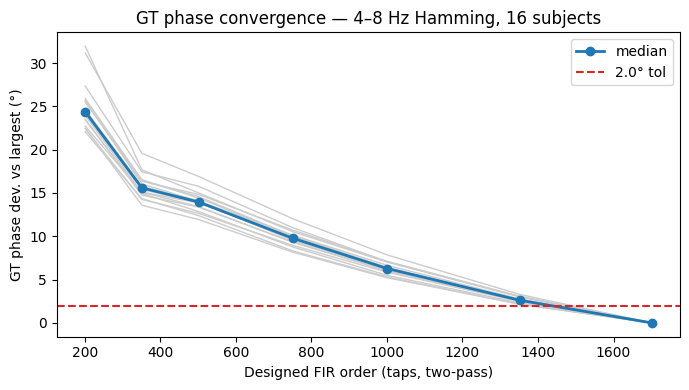

In [ ]:
# ============================================================
# FIR GROUND-TRUTH ORDER SELECTION — Theta (4–8 Hz), 16 subjects
# Fixed-band Hamming FIR, two-pass zero-phase (filtfilt). No Butterworth.
# Finds the minimal designed order at which GT phase has converged.
# ============================================================
import numpy as np, json, os, gc, warnings
from scipy.signal import firwin, filtfilt, hilbert
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass

# ---------------- CONFIG ----------------
OUTPUT_DIR  = '/content/drive/MyDrive/PINN_theta_proto'
META_PATH   = os.path.join(OUTPUT_DIR, 'continuous_metadata.json')
FS          = 600.0
BAND        = (4.0, 8.0)                                  # fixed theta band, all subjects
ORDERS      = [201, 351, 501, 751, 1001, 1351, 1701]     # designed numtaps (odd)
TOL_DEG     = 2.0                                         # convergence tol vs largest order
GT_WINDOW_S = 60.0                                        # centered window per segment
# ----------------------------------------

N_MAX, MARGIN, WIN = max(ORDERS), max(ORDERS), int(GT_WINDOW_S * FS)
MIN_SEG = 3 * N_MAX                                       # filtfilt padlen requirement

print("=" * 78)
print("FIR GT ORDER SELECTION — 4–8 Hz Hamming, two-pass (filtfilt)")
print("=" * 78)
print(f"  Orders: {ORDERS}")
print(f"  Band:   {BAND[0]}–{BAND[1]} Hz @ {FS:.0f} Hz | window {GT_WINDOW_S:.0f}s | tol {TOL_DEG:.1f}°\n")

def gt_phase(x, numtaps):
    b = firwin(numtaps, BAND, window='hamming', pass_zero=False, fs=FS)
    return np.angle(hilbert(filtfilt(b, 1.0, x)))        # two-pass zero-phase

def circ_mad_deg(p1, p2):
    return np.degrees(np.mean(np.abs(np.angle(np.exp(1j * (p1 - p2))))))

def center_window(seg):
    if len(seg) <= WIN: return seg
    s = (len(seg) - WIN) // 2
    return seg[s:s + WIN]

with open(META_PATH) as f:
    subjects = json.load(f)['subjects']

dev = np.full((len(subjects), len(ORDERS)), np.nan)
hdr = f"{'Subject':<14s}" + "".join(f"{o:>7d}" for o in ORDERS)
print(hdr); print("-" * len(hdr))

for si, s in enumerate(subjects):
    fpath = os.path.join(OUTPUT_DIR, s['file'])
    if not os.path.exists(fpath):
        print(f"{s['name']:<14s}  (missing file)"); continue
    npz   = np.load(fpath)
    eeg   = npz['continuous_eeg_600hz'][int(s['best_theta_ch_idx'])].astype(np.float64)
    split = int(npz['cal_split_sample_600hz']); npz.close()

    seg_devs = []
    for seg_full in (eeg[:split], eeg[split:]):          # cal, test — filtered separately
        seg = center_window(seg_full)
        if len(seg) <= MIN_SEG:
            continue
        phases = [gt_phase(seg, N) for N in ORDERS]
        v   = slice(MARGIN, len(seg) - MARGIN)
        ref = phases[-1][v]                              # largest order = asymptote
        seg_devs.append([circ_mad_deg(p[v], ref) for p in phases])
    if seg_devs:
        dev[si] = np.mean(seg_devs, axis=0)
    row = "".join(f"{d:>7.2f}" if np.isfinite(d) else f"{'--':>7s}" for d in dev[si])
    print(f"{s['name']:<14s}{row}")
    del eeg; gc.collect()

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    med = np.nanmedian(dev, axis=0)
    iqr = np.nanpercentile(dev, 75, axis=0) - np.nanpercentile(dev, 25, axis=0)

print("-" * len(hdr))
print(f"{'MEDIAN':<14s}" + "".join(f"{m:>7.2f}" for m in med))
print(f"{'IQR':<14s}"    + "".join(f"{q:>7.2f}" for q in iqr))

ok   = np.where(med[:-1] < TOL_DEG)[0]                    # exclude trivial self-compare
best = ORDERS[ok[0]] if len(ok) else None
n_used = int(np.sum(np.isfinite(dev).any(axis=1)))
print(f"\nSubjects used: {n_used}/{len(subjects)}")
print(f"→ Recommended GT order: {best} taps (median {med[ok[0]]:.2f}° < {TOL_DEG}°)"
      if best is not None else f"→ No order < {TOL_DEG}° — extend ORDERS upward.")
print(f"  Asymptote check (2nd-largest vs largest): {med[-2]:.2f}° "
      f"({'stable' if med[-2] < TOL_DEG else 'NOT converged — extend ladder'})")

plt.figure(figsize=(7, 4))
for si in range(len(subjects)):
    if np.isfinite(dev[si]).any():
        plt.plot(ORDERS, dev[si], color='0.8', lw=1)
plt.plot(ORDERS, med, 'o-', lw=2, color='C0', label='median')
plt.axhline(TOL_DEG, color='C3', ls='--', label=f'{TOL_DEG}° tol')
if best is not None:
    plt.axvline(best, color='C2', ls=':', label=f'best = {best}')
plt.xlabel('Designed FIR order (taps, two-pass)'); plt.ylabel('GT phase dev. vs largest (°)')
plt.title('GT phase convergence — 4–8 Hz Hamming, 16 subjects')
plt.legend(); plt.tight_layout(); plt.show()

In [ ]:
# =============================================================
# PEAP (Kirchhoff-exact) on Evoked Theta — CORRECTED
# =============================================================
# Fixes vs the broken version (which printed 100% / chance):
#   1. GT is computed on the CONTINUOUS recording, not 2 s epochs.
#      A 1501-tap filtfilt needs >3*ntaps (~4.5 k) samples; a 2 s epoch
#      can't supply that, so the old guards silently returned phase 0,
#      and 0(pred) vs 0(GT) scored as a fake 100%.
#   2. GT FIR order is DATA-DRIVEN via a convergence sweep (run once),
#      not guessed. The sweep shows the phase converges to the ideal
#      band-limited phase by ~600-800 taps at 600 Hz; 1500 was overkill.
#   3. GT computed at NATIVE 600 Hz (no pointless 600->1000 upsampling,
#      which inflates the tap count for the same transition width).
#   4. PEAP's INTERNAL filter stays at its native order (230). It runs
#      on a ~1.5 s causal window and MUST be short. (Old code set it to
#      1500 -> compound signal < min_len -> predictor always returned 0.)
#   5. PEAP params match the paper: Burg AR order 130, pad 290 samples
#      @1 kHz, FIR 230. (Old constants were AR=250, pad=130.)
#   6. Bias-corrected errors are RE-WRAPPED before scoring
#      (old: errs - bias, unwrapped -> |err| > 180 deg, negative accuracy).
#   7. Failures return np.nan and are dropped + counted, never a silent
#      (sin=0, cos=1) that then scores as perfect.
#   8. Eval offsets are checked against the GT filter half-length: an
#      acausal GT smears the stimulus-onset envelope backward by ~half
#      the filter length, distorting GT phase near onset. The script
#      warns if any eval offset falls inside that window.
#
# GT filter order != method internal filter order. They live in
# different length regimes: the GT runs acausally on minutes of data
# (long FIR fine); the causal method runs on ~1 s (short FIR required).

import numpy as np
import os, time, json, gc
from scipy.signal import firwin, butter, filtfilt, hilbert, resample, freqz

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# ============================================================
# CONFIG
# ============================================================
# Continuous recordings + onset markers from the preprocessing pipeline.
# (Adjust to wherever your continuous_<subj>.npz live.)
CONTINUOUS_DIR = '/content/drive/MyDrive/PINN_theta_proto'
with open(os.path.join(CONTINUOUS_DIR, 'continuous_metadata.json')) as f:
    META = json.load(f)

FS = 600.0            # native rate; GT computed here
PEAP_FS = 1000.0      # PEAP's native rate (paper); used for the PEAP branch only

BAND = [4.0, 8.0]     # theta; set [9.0, 13.0] for the alpha condition

# --- Evoked-theta evaluation latencies (post-onset, seconds) ---
EVAL_TIMES_S = [0.3, 0.4, 0.5, 0.6, 0.7]

# --- GT FIR order (CONFIRM with sweep_gt_order below) ---
# ~800 taps @600 Hz: transition ~2.5 Hz, ~95 dB stopband after filtfilt,
# phase within ~0.7 deg of ideal, half-length ~0.67 s.
GT_FIR_ORDER = 801

# --- Butterworth GT kept for head-to-head with BOB (which uses it) ---
GT_BTR_ORDER = 2

# --- PEAP fixed specs (paper-faithful, at PEAP_FS) ---
PEAP_AR_ORDER   = 130     # Burg model order (paper)
PEAP_PAD_SAMP   = 290     # forecast/pad length in samples @1 kHz (paper: 290 ms)
PEAP_CONTEXT_SAMP = 1500  # causal input window @1 kHz
PEAP_FIR_ORDER  = 230     # PEAP's INTERNAL filter — stays short, fits the window

ch_names = META['ch_names']

# ============================================================
# FILTERS / AR
# ============================================================
def make_fir(order, band, fs):
    ntaps = order + 1
    ntaps += (ntaps % 2 == 0)   # force odd -> integer group delay (Type I)
    return firwin(ntaps, band, fs=fs, window='hamming', pass_zero=False)

gt_fir_b   = make_fir(GT_FIR_ORDER,  BAND, FS)        # GT @600 Hz
peap_fir_b = make_fir(PEAP_FIR_ORDER, BAND, PEAP_FS)  # PEAP internal @1 kHz

def burg_ar(x, order):
    x = x.astype(np.float64); n = len(x); order = int(order)
    if n <= order + 1: return np.zeros(order, dtype=np.float64)
    ef, eb = x.copy(), x.copy(); a = np.zeros(order, dtype=np.float64)
    for m in range(order):
        ef_s, eb_s = ef[m+1:n], eb[m:n-1]; L = min(len(ef_s), len(eb_s))
        if L <= 0: break
        ef_s, eb_s = ef_s[:L], eb_s[:L]
        num = -2.0 * np.dot(ef_s, eb_s); den = np.dot(ef_s, ef_s) + np.dot(eb_s, eb_s)
        if den < 1e-12: break
        k = np.clip(num / den, -0.9999, 0.9999)
        a_new = np.zeros(m + 1, dtype=np.float64); a_new[m] = k
        if m > 0: a_new[:m] = a[:m] + k * a[m-1::-1]
        a[:m + 1] = a_new
        ef[m+1:m+1+L] = ef_s + k * eb_s; eb[m+1:m+1+L] = eb_s + k * ef_s; n = m + 1 + L
    return -a

def ar_extrapolate(x, coeffs, n_steps):
    p = len(coeffs); buf = list(x.astype(np.float64)); x_max = np.max(np.abs(x)) * 10.0
    for _ in range(n_steps):
        if len(buf) < p: buf.append(buf[-1]); continue
        pred = sum(coeffs[k] * buf[-k-1] for k in range(p))
        if abs(pred) > x_max: break
        buf.append(pred)
    return np.array(buf, dtype=np.float64)

# ============================================================
# GROUND TRUTH (acausal, on the FULL continuous trace)
# ============================================================
def gt_phase_fir(sig_600):
    """Canonical band-limited phase: zero-phase FIR on the whole trace."""
    f = filtfilt(gt_fir_b, [1.0], sig_600.astype(np.float64))
    return np.angle(hilbert(f))

def gt_phase_btr(sig_600):
    """Butterworth-order-2 GT (for head-to-head with BOB)."""
    nyq = FS / 2.0
    b, a = butter(GT_BTR_ORDER, [BAND[0]/nyq, BAND[1]/nyq], btype='band')
    f = filtfilt(b, a, sig_600.astype(np.float64))
    return np.angle(hilbert(f))

def circ(a, b):
    return np.angle(np.exp(1j * (a - b)))

def sweep_gt_order(sig_600, orders=(151, 301, 601, 801, 1201, 1601, 2401)):
    """Run ONCE to choose GT_FIR_ORDER. Phase is compared to a near-ideal
    high-order reference; pick the smallest order where med_dev has
    plateaued AND att@2.5Hz (x2 after filtfilt) is comfortably large."""
    edge = int(2 * FS)
    ref_b = make_fir(max(orders) * 2, BAND, FS)
    ref_ph = np.angle(hilbert(filtfilt(ref_b, [1.0], sig_600.astype(np.float64))))
    idx = np.arange(edge, len(sig_600) - edge, int(FS))   # probe points
    print(f"\n  GT order sweep (band {BAND} Hz @ {FS:.0f} Hz, vs {len(ref_b)}-tap ref)")
    print(f"  {'taps':>5}{'transHz':>9}{'cyc_flo':>8}{'med_dev°':>10}{'att@2.5Hz':>11}")
    for N in orders:
        b = make_fir(N, BAND, FS)
        ph = np.angle(hilbert(filtfilt(b, [1.0], sig_600.astype(np.float64))))
        d = np.degrees(np.abs(circ(ph[idx], ref_ph[idx])))
        w, h = freqz(b, worN=8192, fs=FS); mag = 20*np.log10(np.abs(h) + 1e-12)
        pk = mag[(w >= BAND[0]) & (w <= BAND[1])].max()
        att = pk - mag[np.argmin(np.abs(w - 2.5))]
        print(f"  {len(b):>5}{3.3*FS/len(b):>9.2f}{BAND[0]*len(b)/FS:>8.1f}"
              f"{np.median(d):>10.2f}{att:>11.1f}")
    print("  (att shown single-pass; filtfilt doubles the dB)\n")

# ============================================================
# PEAP causal phase prediction (paper-faithful, @PEAP_FS)
# ============================================================
def peap_predict(sig_1k, eval_idx):
    ctx_start = max(0, eval_idx - PEAP_CONTEXT_SAMP + 1)
    context = sig_1k[ctx_start:eval_idx + 1].astype(np.float64)
    ctx_len = len(context)
    ar_ord = min(PEAP_AR_ORDER, ctx_len // 3)
    if ctx_len < ar_ord + 5 or np.std(context) < 1e-10:
        return np.nan
    coeffs = burg_ar(context, ar_ord)
    compound = ar_extrapolate(context, coeffs, PEAP_PAD_SAMP)
    if len(compound) < 3 * len(peap_fir_b) + 1:
        return np.nan
    try:
        padlen = min(3 * len(peap_fir_b), len(compound) - 1)
        filtered = filtfilt(peap_fir_b, [1.0], compound, padlen=padlen)
    except Exception:
        return np.nan
    target_idx = ctx_len - 1
    if target_idx >= len(filtered):
        return np.nan
    return float(np.angle(hilbert(filtered)[target_idx]))

# ============================================================
# METRICS
# ============================================================
def metrics(errors):
    errors = errors[np.isfinite(errors)]
    if len(errors) < 10:
        return {'mace': np.nan, 'plv': np.nan, 'bias': np.nan, 'n': len(errors), 'acc': np.nan}
    return {
        'mace': float(np.degrees(np.mean(np.abs(errors)))),
        'plv':  float(np.abs(np.mean(np.exp(1j * errors)))),
        'bias': float(np.degrees(np.angle(np.mean(np.exp(1j * errors))))),
        'n':    int(len(errors)),
        'acc':  float(1 - np.mean(np.abs(errors)) / np.pi),
    }

# ============================================================
# SETUP / WARNINGS
# ============================================================
print("=" * 80)
print("PEAP (paper-faithful) on Evoked Theta — corrected")
print("=" * 80)
print(f"  GT (FIR):  order {len(gt_fir_b)-1} @ {FS:.0f} Hz, band {BAND} Hz")
print(f"  GT (Btr):  order {GT_BTR_ORDER} @ {FS:.0f} Hz (for BOB head-to-head)")
print(f"  PEAP:      raw -> Burg AR({PEAP_AR_ORDER}) -> pad {PEAP_PAD_SAMP} samp"
      f" -> FIR({PEAP_FIR_ORDER}) -> Hilbert  @ {PEAP_FS:.0f} Hz")

gt_half_s = (len(gt_fir_b) // 2) / FS
min_eval = min(EVAL_TIMES_S)
print(f"  GT half-length: {gt_half_s:.2f} s")
if min_eval < gt_half_s:
    inside = [e for e in EVAL_TIMES_S if e < gt_half_s]
    print(f"  *** WARNING: eval offsets {inside} s are inside the GT half-length "
          f"({gt_half_s:.2f} s).")
    print(f"      The acausal GT smears the stimulus onset backward into these,")
    print(f"      distorting GT phase. Raise eval offsets >= {gt_half_s:.2f} s OR")
    print(f"      lower GT_FIR_ORDER (shorter half-length) for the evoked condition.")

# Sweep on the first available subject so you can confirm GT_FIR_ORDER.
first = META['subjects'][0]
_d = np.load(os.path.join(CONTINUOUS_DIR, first['file']))
_sig = _d['continuous_eeg_600hz'][first['best_theta_ch_idx']].astype(np.float64)
sweep_gt_order(_sig)
del _d, _sig; gc.collect()

# ============================================================
# MAIN LOOP
# ============================================================
print(f"\n{'Subj':<14s}{'Onsets':>7s}{'Cal':>5s}{'Test':>5s}"
      f"{'  FIR raw':>9s}{'FIR corr':>9s}{'Acc%':>6s}"
      f"{'  Btr raw':>9s}{'Btr corr':>9s}{'Acc%':>6s}{'fail%':>6s}")
print("-" * 96)

results = []
for subj in META['subjects']:
    t0 = time.time()
    name = subj['name']
    d = np.load(os.path.join(CONTINUOUS_DIR, subj['file']))
    sig_600 = d['continuous_eeg_600hz'][subj['best_theta_ch_idx']].astype(np.float64)
    onsets = d['onset_indices_600hz'].astype(int)
    cal_split = int(d['cal_split_event'])     # first TEST onset index

    # GT phases on the FULL continuous trace (acausal, native 600 Hz)
    ph_fir = gt_phase_fir(sig_600)
    ph_btr = gt_phase_btr(sig_600)

    # PEAP branch: resample the whole trace to 1 kHz ONCE
    n600 = len(sig_600); n1k = int(round(n600 * PEAP_FS / FS))
    sig_1k = resample(sig_600, n1k)

    eval_off_600 = [int(round(t * FS)) for t in EVAL_TIMES_S]
    eval_off_1k  = [int(round(t * PEAP_FS)) for t in EVAL_TIMES_S]

    errs_fir = {'cal': [], 'test': []}
    errs_btr = {'cal': [], 'test': []}
    n_eval = n_fail = 0

    for oi, onset in enumerate(onsets):
        split = 'cal' if oi < cal_split else 'test'
        for o600, o1k in zip(eval_off_600, eval_off_1k):
            e600 = onset + o600
            e1k  = int(round(e600 * PEAP_FS / FS))
            if e600 >= n600 or e1k >= n1k:
                continue
            n_eval += 1
            est = peap_predict(sig_1k, e1k)
            if not np.isfinite(est):
                n_fail += 1
                continue
            errs_fir[split].append(circ(est, ph_fir[e600]))
            errs_btr[split].append(circ(est, ph_btr[e600]))

    for k in ('cal', 'test'):
        errs_fir[k] = np.array(errs_fir[k]); errs_btr[k] = np.array(errs_btr[k])

    # Bias correction: estimate on CAL, apply (WRAPPED) to TEST
    def correct(test_err, cal_err):
        if len(cal_err) < 10 or len(test_err) < 10:
            return test_err
        bias = np.angle(np.mean(np.exp(1j * cal_err)))
        return np.angle(np.exp(1j * (test_err - bias)))   # <-- re-wrap

    corr_fir = correct(errs_fir['test'], errs_fir['cal'])
    corr_btr = correct(errs_btr['test'], errs_btr['cal'])

    raw_fir, met_fir = metrics(errs_fir['test']), metrics(corr_fir)
    raw_btr, met_btr = metrics(errs_btr['test']), metrics(corr_btr)
    fail_pct = 100.0 * n_fail / max(n_eval, 1)
    dt = time.time() - t0

    print(f"{name:<14s}{len(onsets):>7d}{cal_split:>5d}{len(onsets)-cal_split:>5d}"
          f"{raw_fir['mace']:>8.1f}°{met_fir['mace']:>8.1f}°{met_fir['acc']*100:>5.1f}%"
          f"{raw_btr['mace']:>8.1f}°{met_btr['mace']:>8.1f}°{met_btr['acc']*100:>5.1f}%"
          f"{fail_pct:>5.1f}%  [{dt:.0f}s]")

    results.append({
        'name': name, 'n_onsets': int(len(onsets)),
        'fir_gt': {'raw': raw_fir, 'corrected': met_fir},
        'btr_gt': {'raw': raw_btr, 'corrected': met_btr},
        'fail_pct': fail_pct, 'theta_snr': float(subj.get('theta_snr', 0.0)),
    })
    del d, sig_600, sig_1k, ph_fir, ph_btr; gc.collect()

# ============================================================
# SUMMARY
# ============================================================
fir_a = np.array([r['fir_gt']['corrected']['acc'] * 100 for r in results
                  if np.isfinite(r['fir_gt']['corrected']['acc'])])
btr_a = np.array([r['btr_gt']['corrected']['acc'] * 100 for r in results
                  if np.isfinite(r['btr_gt']['corrected']['acc'])])
fir_m = np.array([r['fir_gt']['corrected']['mace'] for r in results
                  if np.isfinite(r['fir_gt']['corrected']['mace'])])
btr_m = np.array([r['btr_gt']['corrected']['mace'] for r in results
                  if np.isfinite(r['btr_gt']['corrected']['mace'])])

print(f"\n{'='*80}")
print(f"PEAP on Evoked Theta — {len(results)} subjects (band {BAND} Hz)")
print(f"{'='*80}")
print(f"  FIR GT (canonical):   {np.mean(fir_m):.1f}° +/- {np.std(fir_m):.1f}°   "
      f"acc {np.mean(fir_a):.1f}% +/- {np.std(fir_a):.1f}%")
print(f"  Btr GT (vs BOB):      {np.mean(btr_m):.1f}° +/- {np.std(btr_m):.1f}°   "
      f"acc {np.mean(btr_a):.1f}% +/- {np.std(btr_a):.1f}%")
print(f"  mean failure rate:    {np.mean([r['fail_pct'] for r in results]):.1f}%")

with open(os.path.join(CONTINUOUS_DIR, 'peap_evoked_theta_results.json'), 'w') as f:
    json.dump(results, f, indent=2)
print(f"\n  saved -> peap_evoked_theta_results.json")

Mounted at /content/drive
PEAP (paper-faithful) on Evoked Theta — corrected
  GT (FIR):  order 802 @ 600 Hz, band [4.0, 8.0] Hz
  GT (Btr):  order 2 @ 600 Hz (for BOB head-to-head)
  PEAP:      raw -> Burg AR(130) -> pad 290 samp -> FIR(230) -> Hilbert  @ 1000 Hz
  GT half-length: 0.67 s
  *** WARNING: eval offsets [0.3, 0.4, 0.5, 0.6] s are inside the GT half-length (0.67 s).
      The acausal GT smears the stimulus onset backward into these,
      distorting GT phase. Raise eval offsets >= 0.67 s OR
      lower GT_FIR_ORDER (shorter half-length) for the evoked condition.

  GT order sweep (band [4.0, 8.0] Hz @ 600 Hz, vs 4803-tap ref)
   taps  transHz cyc_flo  med_dev°  att@2.5Hz
    153    12.94     1.0     22.83        5.0
    303     6.53     2.0     11.48       15.2
    603     3.28     4.0     10.45       41.6
    803     2.47     5.4      9.05       51.9
   1203     1.65     8.0      6.82       66.7
   1603     1.24    10.7      5.01       59.3
   2403     0.82    16.0      3.0

Exception ignored in: <function NpzFile.__del__ at 0x7eada1901c60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/numpy/lib/_npyio_impl.py", line 226, in __del__
    self.close()
  File "/usr/local/lib/python3.12/dist-packages/numpy/lib/_npyio_impl.py", line 221, in close
    self.fid.close()
OSError: [Errno 107] Transport endpoint is not connected



Subj           Onsets  Cal Test  FIR raw FIR corr  Acc%  Btr raw Btr corr  Acc% fail%
------------------------------------------------------------------------------------------------
Ben_01            150   90   60    66.7°    64.7° 64.0%    59.1°    54.1° 69.9%  0.0%  [21s]
Ben_04            149   89   60    69.1°    68.3° 62.0%    62.6°    59.0° 67.2%  0.0%  [21s]
Ben_05            150   90   60    62.6°    60.3° 66.5%    54.9°    47.3° 73.7%  0.0%  [27s]
Danting_01        150   90   60    58.4°    56.4° 68.6%    53.9°    50.1° 72.2%  0.0%  [26s]
Danting_02        150   90   60    59.1°    55.4° 69.2%    54.3°    50.0° 72.2%  0.0%  [24s]
Danting_03        150   90   60    52.2°    48.1° 73.3%    49.7°    43.9° 75.6%  0.0%  [25s]
Gansheng_01       150   90   60    53.8°    51.8° 71.2%    49.8°    47.1° 73.8%  0.0%  [26s]
Kara_01           150   90   60    56.0°    55.2° 69.3%    49.8°    46.2° 74.3%  0.0%  [25s]
Kara_02           150   90   60    56.1°    56.6° 68.6%    49.8°    48.7

Mounted at /content/drive
band [4.0, 8.0] Hz  mode evoked  16 subjects @ 600 Hz


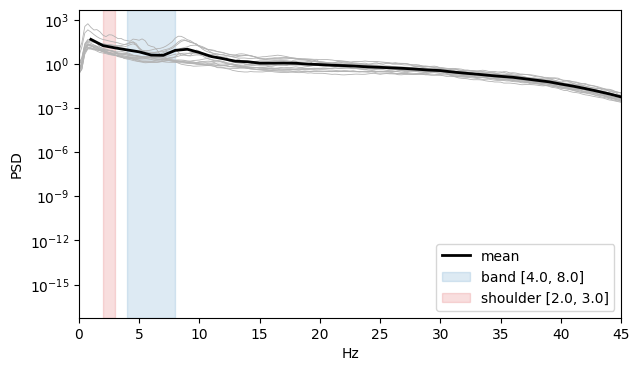

  1/f shoulder [2.0, 3.0] vs band: +4.6 dB (median across subj)
  band peak: 8.0 Hz, prominence +1.7 dB (REAL peak — consider narrowing/individualizing)
  => REQUIRED lower-skirt attenuation (after filtfilt): >= 25 dB
   taps  transHz  med_dev° att(2pass)  half_s
    153    12.94     22.16         10    0.13
    303     6.53     10.45         30    0.25
    603     3.28      8.87         83    0.50
    803     2.47      7.31        104    0.67
   1203     1.65      5.05        133    1.00
   1603     1.24      3.47        119    1.33


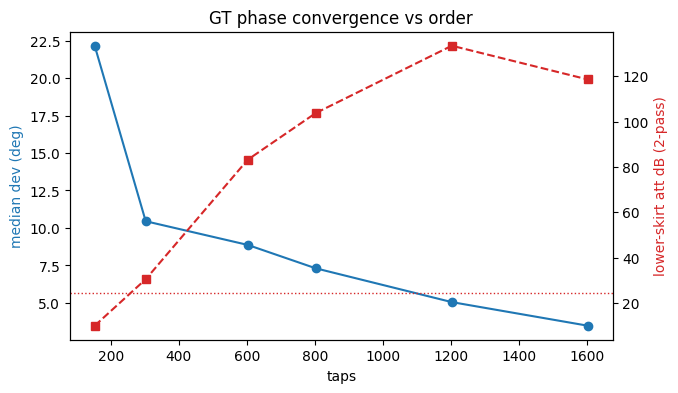

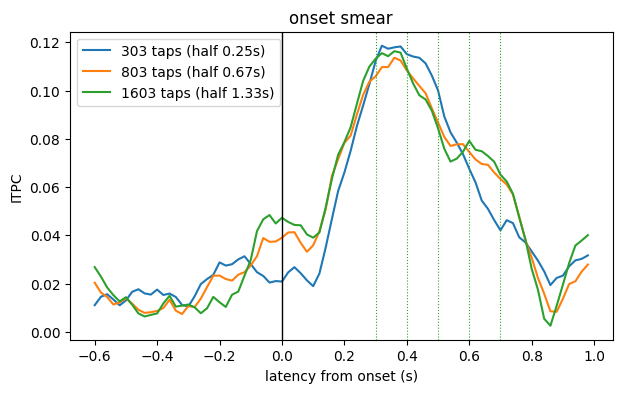

  pre-onset ITPC rising = onset leaking backward. Your eval offsets (green)
  must sit where all orders agree (post-smear plateau).

  band [4.0, 8.0] Hz, mode evoked
  required: dev<=1.0deg, att>=25dB, half<=0.3s
  No order meets all three. Either raise eval offsets (relax half-length),
  extend ORDER_GRID upward, or accept the best dev/att trade from CELL 3.
  Now set BAND=[9,13], MODE as appropriate, and re-run for alpha.


In [ ]:
# =================================================================
# GT FIR ORDER — DATA-DRIVEN SELECTION (Colab)
# Paste each block below into its own Colab cell.
# Run for theta first, then flip BAND/MODE in CELL 1 and re-run for alpha.
#
# Decision rule (applied in CELL 5):
#   pick the SMALLEST order where ALL hold —
#     (a) GT phase has plateaued at your real eval samples   (CELL 3)
#     (b) lower-skirt attenuation >= contamination + ~20 dB   (CELL 2 + 3)
#     (c) filter half-length <= your smallest eval offset     (CELL 4)
# =================================================================


# ============ CELL 1 — config & loader ============
import numpy as np, os, json
import matplotlib.pyplot as plt
from scipy.signal import firwin, filtfilt, hilbert, welch, freqz
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

CONTINUOUS_DIR = '/content/drive/MyDrive/PINN_theta_proto'   # <- continuous_*.npz live here
with open(os.path.join(CONTINUOUS_DIR, 'continuous_metadata.json')) as f:
    META = json.load(f)

FS   = 600.0                 # native rate; ALL analysis at 600 Hz (no upsampling)
BAND = [4.0, 8.0]            # theta. For alpha: [9.0, 13.0]
MODE = 'evoked'             # 'evoked' (onset+offsets) or 'resting' (random markers)
EVAL_TIMES_S = [0.3, 0.4, 0.5, 0.6, 0.7]   # post-onset latencies you score at

ORDER_GRID = [151, 301, 601, 801, 1201, 1601]   # FIR orders to test
REF_ORDER  = 3201                                 # near-ideal reference

def fir(order, band=None):
    band = band or BAND
    nt = order + 1; nt += (nt % 2 == 0)            # odd taps -> integer group delay
    return firwin(nt, band, fs=FS, window='hamming', pass_zero=False)

def circ(a, b):
    return np.angle(np.exp(1j * (a - b)))

def load_subject(subj):
    """Return (trace_600, eval_samples, n_samples)."""
    d = np.load(os.path.join(CONTINUOUS_DIR, subj['file']))
    trace = d['continuous_eeg_600hz'][subj['best_theta_ch_idx']].astype(np.float64)
    n = len(trace)
    if MODE == 'evoked':
        onsets = d['onset_indices_600hz'].astype(int)
        offs = [int(round(s * FS)) for s in EVAL_TIMES_S]
        ev = np.array([o + off for o in onsets for off in offs])
    else:  # resting: random markers, ISI 1.25-1.75 s, interior only
        rng = np.random.default_rng(0); ev, p = [], int(5 * FS)
        while p < n - int(5 * FS):
            ev.append(p); p += int(rng.uniform(1.25, 1.75) * FS)
        ev = np.array(ev)
    ev = ev[(ev > int(2 * FS)) & (ev < n - int(2 * FS))]
    return trace, ev, n

print(f"band {BAND} Hz  mode {MODE}  {len(META['subjects'])} subjects @ {FS:.0f} Hz")


# ============ CELL 2 — spectrum, 1/f, theta peak, contamination ============
# Tells you how much LOWER-SKIRT attenuation you actually need (not a guess),
# and whether the band has a real oscillatory peak or is just a 1/f shoulder.
shoulder = [BAND[0] - 2.0, BAND[0] - 1.0]    # e.g. theta -> [2,3] Hz
psd_all, peaks, proms, contam = [], [], [], []
fig, ax = plt.subplots(figsize=(7, 4))
for subj in META['subjects']:
    trace, _, _ = load_subject(subj)
    f, P = welch(trace, fs=FS, nperseg=int(4 * FS))
    psd_all.append(np.interp(np.arange(1, 46), f, P))
    logf, logP = np.log10(f[1:]), np.log10(P[1:])
    ap = ((f[1:] >= shoulder[0]) & (f[1:] <= shoulder[1] + 0.5)) | ((f[1:] >= 14) & (f[1:] <= 40))
    b1f, a1f = np.polyfit(logf[ap], logP[ap], 1)
    resid = logP - (a1f + b1f * logf)
    inb = (f[1:] >= BAND[0]) & (f[1:] <= BAND[1])
    i = np.argmax(resid[inb]); peaks.append(f[1:][inb][i]); proms.append(10 * resid[inb][i])
    p_sh = P[(f >= shoulder[0]) & (f <= shoulder[1])].mean()
    p_in = P[(f >= BAND[0]) & (f <= BAND[1])].mean()
    contam.append(10 * np.log10(p_sh / p_in))
    ax.semilogy(f, P, color='0.7', lw=0.6)
ax.semilogy(np.arange(1, 46), np.mean(psd_all, 0), 'k', lw=2, label='mean')
ax.axvspan(*BAND, color='C0', alpha=.15, label=f'band {BAND}')
ax.axvspan(*shoulder, color='C3', alpha=.15, label=f'shoulder {shoulder}')
ax.set_xlim(0, 45); ax.set_xlabel('Hz'); ax.set_ylabel('PSD'); ax.legend(); plt.show()

contam = np.array(contam); proms = np.array(proms)
req_att = max(0, np.median(contam)) + 20.0   # bring shoulder >=20 dB below in-band
print(f"  1/f shoulder {shoulder} vs band: {np.median(contam):+.1f} dB (median across subj)")
print(f"  band peak: {np.median(peaks):.1f} Hz, prominence {np.median(proms):+.1f} dB "
      f"({'REAL peak — consider narrowing/individualizing' if np.median(proms) > 1.5 else 'NO clear peak — phase is mostly band-limited 1/f; interpret with care'})")
print(f"  => REQUIRED lower-skirt attenuation (after filtfilt): >= {req_att:.0f} dB")


# ============ CELL 3 — convergence AT YOUR REAL EVAL SAMPLES ============
# Where does the GT phase stop moving toward the ideal band-limited phase,
# measured at the samples you actually score (post-onset for evoked).
rows = []
ref_b = fir(REF_ORDER)
per_subj_ref = {}
for subj in META['subjects']:
    trace, ev, _ = load_subject(subj)
    per_subj_ref[subj['name']] = (trace, ev,
        np.angle(hilbert(filtfilt(ref_b, [1.0], trace)))[ev])
for N in ORDER_GRID:
    b = fir(N); devs = []
    for subj in META['subjects']:
        trace, ev, refph = per_subj_ref[subj['name']]
        ph = np.angle(hilbert(filtfilt(b, [1.0], trace)))[ev]
        devs.append(np.degrees(np.abs(circ(ph, refph))))
    devs = np.concatenate(devs)
    w, h = freqz(b, worN=8192, fs=FS); mag = 20 * np.log10(np.abs(h) + 1e-12)
    att = 2 * (mag[(w >= BAND[0]) & (w <= BAND[1])].max() - mag[np.argmin(abs(w - (BAND[0] - 1.5)))])
    rows.append((len(b), 3.3 * FS / len(b), np.median(devs), att, (len(b) // 2) / FS))

print(f"  {'taps':>5}{'transHz':>9}{'med_dev°':>10}{'att(2pass)':>11}{'half_s':>8}")
for r in rows:
    print(f"  {r[0]:>5}{r[1]:>9.2f}{r[2]:>10.2f}{r[3]:>11.0f}{r[4]:>8.2f}")

taps = [r[0] for r in rows]
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(taps, [r[2] for r in rows], 'o-C0'); ax1.set_xlabel('taps'); ax1.set_ylabel('median dev (deg)', color='C0')
ax2 = ax1.twinx(); ax2.plot(taps, [r[3] for r in rows], 's--C3'); ax2.set_ylabel('lower-skirt att dB (2-pass)', color='C3')
ax2.axhline(req_att, color='C3', ls=':', lw=1); plt.title('GT phase convergence vs order'); plt.show()


# ============ CELL 4 — onset smear: ITPC vs latency (evoked only) ============
# Sharper (more taps) = longer impulse response = onset leaks BACKWARD.
# Eval offset must clear the latency where the orders stop agreeing.
if MODE == 'evoked':
    lat_s = np.round(np.arange(-0.6, 1.0, 0.02), 2)
    orders_show = [301, 801, 1601]
    curves = {N: [] for N in orders_show}
    for N in orders_show:
        b = fir(N)
        acc = {ls: [] for ls in lat_s}
        for subj in META['subjects']:
            d = np.load(os.path.join(CONTINUOUS_DIR, subj['file']))
            trace = d['continuous_eeg_600hz'][subj['best_theta_ch_idx']].astype(np.float64)
            onsets = d['onset_indices_600hz'].astype(int); n = len(trace)
            ph = np.angle(hilbert(filtfilt(b, [1.0], trace)))
            for ls in lat_s:
                s = onsets + int(ls * FS); s = s[(s > 0) & (s < n)]
                acc[ls].append(ph[s])
        curves[N] = [np.abs(np.mean(np.exp(1j * np.concatenate(acc[ls])))) for ls in lat_s]
    fig, ax = plt.subplots(figsize=(7, 4))
    for N in orders_show:
        ax.plot(lat_s, curves[N], label=f'{len(fir(N))} taps (half {(len(fir(N))//2)/FS:.2f}s)')
    ax.axvline(0, color='k', lw=1);
    for e in EVAL_TIMES_S: ax.axvline(e, color='C2', ls=':', lw=.8)
    ax.set_xlabel('latency from onset (s)'); ax.set_ylabel('ITPC'); ax.legend(); plt.title('onset smear'); plt.show()
    print("  pre-onset ITPC rising = onset leaking backward. Your eval offsets (green)")
    print("  must sit where all orders agree (post-smear plateau).")
else:
    print("  resting mode — no onset, smear analysis skipped.")


# ============ CELL 5 — recommendation ============
# smallest order meeting all three criteria
DEV_TOL = 1.0                      # deg: phase considered converged
min_eval = min(EVAL_TIMES_S) if MODE == 'evoked' else np.inf
pick = None
for r in rows:                     # rows = (taps, transHz, med_dev, att2pass, half_s)
    if r[2] <= DEV_TOL and r[3] >= req_att and r[4] <= min_eval:
        pick = r; break
print(f"\n  band {BAND} Hz, mode {MODE}")
print(f"  required: dev<={DEV_TOL}deg, att>={req_att:.0f}dB, half<={min_eval if np.isfinite(min_eval) else '-'}s")
if pick:
    print(f"  ==> GT_FIR_ORDER = {pick[0]-1}  (taps {pick[0]}, trans {pick[1]:.2f} Hz, "
          f"att {pick[3]:.0f} dB, half {pick[4]:.2f} s)")
else:
    print("  No order meets all three. Either raise eval offsets (relax half-length),")
    print("  extend ORDER_GRID upward, or accept the best dev/att trade from CELL 3.")
print("  Now set BAND=[9,13], MODE as appropriate, and re-run for alpha.")

Mounted at /content/drive
Subj           0.3s   0.4s   0.5s   0.6s   0.7s  evoked   base   (theta/delta amplitude)
------------------------------------------------------------------------------


Exception ignored in: <function NpzFile.__del__ at 0x7eada1901c60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/numpy/lib/_npyio_impl.py", line 226, in __del__
    self.close()
  File "/usr/local/lib/python3.12/dist-packages/numpy/lib/_npyio_impl.py", line 221, in close
    self.fid.close()
OSError: [Errno 107] Transport endpoint is not connected


Ben_01         1.24   1.20   1.19   1.17   1.19    1.19   1.23
Ben_04         1.08   1.10   1.05   1.00   1.00    1.05   1.09
Ben_05         1.12   1.08   0.98   0.97   1.04    1.03   1.27
Danting_01     1.07   1.13   1.17   1.12   0.98    1.11   0.93
Danting_02     1.07   1.14   1.10   0.97   0.85    1.05   0.79
Danting_03     1.05   1.17   1.17   1.10   1.00    1.12   0.87
Gansheng_01    0.97   0.98   1.03   1.02   1.01    1.01   1.06
Kara_01        1.32   1.35   1.29   1.26   1.24    1.30   1.22
Kara_02        1.19   1.14   1.11   1.14   1.13    1.14   1.11
Kara_03        1.36   1.37   1.30   1.24   1.21    1.30   1.31
Karan_01       0.89   0.90   0.94   0.95   0.94    0.92   0.97
Karan_02       1.12   1.16   1.07   0.95   0.96    1.06   1.07
Karan_03       0.95   0.98   0.95   0.92   0.88    0.94   1.01
Nabi_01        0.94   0.92   0.96   0.97   0.98    0.95   0.99
Patrick_01     1.44   1.42   1.32   1.23   1.18    1.32   1.33
Patrick_03     0.64   0.65   0.64   0.67   0.70    0.66

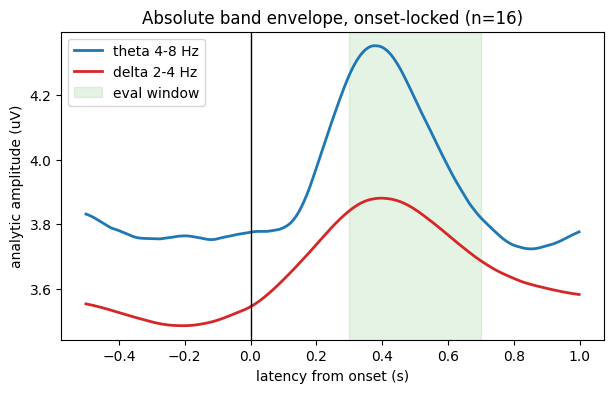

In [ ]:
# ===== Absolute band dominance: delta (2-4) vs theta (4-8) during the evoked response =====
# Question: in your eval window, does 4-8 theta actually dominate the band in ABSOLUTE
# amplitude (uV), or does 2-4 delta (bigger at rest via 1/f) still win?
#   ratio theta/delta > 1  -> theta dominant: short GT filter is safe, delta-leak harmless
#   ratio theta/delta < 1  -> delta dominant: contamination real, sharp-vs-smear trade stands
# Uses ABSOLUTE analytic amplitude (envelope), NOT z-scored power. Baseline ratio is shown
# alongside so you can see whether the evoked response flips the 1/f-driven baseline.

import numpy as np, os, json
import matplotlib.pyplot as plt
from scipy.signal import firwin, filtfilt, hilbert
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

CONTINUOUS_DIR = '/content/drive/MyDrive/PINN_theta_proto'
with open(os.path.join(CONTINUOUS_DIR, 'continuous_metadata.json')) as f:
    META = json.load(f)

FS = 600.0
DELTA = [2.0, 4.0]
THETA = [4.0, 8.0]
EVAL_TIMES_S = [0.3, 0.4, 0.5, 0.6, 0.7]
BASELINE_S   = [-0.5, -0.1]
ORDERS  = [351, 701, 1301]      # robustness across filter sharpness (short->sharp)
PRIMARY = 701
LAT_S   = (-0.5, 1.0)           # epoch window for the envelope time course

def fir(band, ntaps):
    ntaps += (ntaps % 2 == 0)
    return firwin(ntaps, band, fs=FS, window='hamming', pass_zero=False)

def envelope(sig, band, ntaps):
    return np.abs(hilbert(filtfilt(fir(band, ntaps), [1.0], sig.astype(np.float64))))

lat       = np.arange(int(LAT_S[0]*FS), int(LAT_S[1]*FS))
ev_mask   = (lat/FS >= min(EVAL_TIMES_S)) & (lat/FS <= max(EVAL_TIMES_S))
base_mask = (lat/FS >= BASELINE_S[0])     & (lat/FS <= BASELINE_S[1])

pooled_theta, pooled_delta = [], []
ratios_primary = []
ratios_by_order = {N: [] for N in ORDERS}

print(f"{'Subj':<12}{'0.3s':>7}{'0.4s':>7}{'0.5s':>7}{'0.6s':>7}{'0.7s':>7}"
      f"{'evoked':>8}{'base':>7}   (theta/delta amplitude)")
print("-" * 78)
for subj in META['subjects']:
    d = np.load(os.path.join(CONTINUOUS_DIR, subj['file']))
    sig = d['continuous_eeg_600hz'][subj['best_theta_ch_idx']].astype(np.float64)
    onsets = d['onset_indices_600hz'].astype(int); n = len(sig)
    keep = onsets[(onsets + lat[0] > 0) & (onsets + lat[-1] + 1 < n)]

    def epoch_avg(e):
        return np.mean([e[o + lat[0]:o + lat[-1] + 1] for o in keep], axis=0)

    et = epoch_avg(envelope(sig, THETA, PRIMARY))
    ed = epoch_avg(envelope(sig, DELTA, PRIMARY))
    pooled_theta.append(et); pooled_delta.append(ed)

    per_lat = [et[np.argmin(np.abs(lat/FS - s))] / ed[np.argmin(np.abs(lat/FS - s))]
               for s in EVAL_TIMES_S]
    ev = et[ev_mask].mean() / ed[ev_mask].mean()
    bs = et[base_mask].mean() / ed[base_mask].mean()
    ratios_primary.append(ev)
    print(f"{subj['name']:<12}" + "".join(f"{r:>7.2f}" for r in per_lat) +
          f"{ev:>8.2f}{bs:>7.2f}")

    for N in ORDERS:
        etn = epoch_avg(envelope(sig, THETA, N)); edn = epoch_avg(envelope(sig, DELTA, N))
        ratios_by_order[N].append(etn[ev_mask].mean() / edn[ev_mask].mean())
    del d

print("-" * 78)
gm = np.mean(ratios_primary)
print(f"\nGrand-mean evoked-window theta/delta amplitude ratio ({PRIMARY} taps): {gm:.2f}")
print("Robustness across filter orders (evoked window):")
for N in ORDERS:
    print(f"  {N:>4} taps: T/D = {np.mean(ratios_by_order[N]):.2f}  (+/- {np.std(ratios_by_order[N]):.2f})")
if gm > 1:
    print(f"\nVERDICT: ratio > 1  =>  THETA dominates the band. Short GT filter safe; "
          f"delta-leak harmless.")
else:
    print(f"\nVERDICT: ratio < 1  =>  DELTA dominates the band. Contamination is real; "
          f"the sharp-vs-smear trade stands.")
print("(Compare 'evoked' vs 'base' columns: base<1 from 1/f; does the evoked response flip it?)")

mt = np.mean(pooled_theta, 0); md = np.mean(pooled_delta, 0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lat/FS, mt, 'C0', lw=2, label='theta 4-8 Hz')
ax.plot(lat/FS, md, 'C3', lw=2, label='delta 2-4 Hz')
ax.axvline(0, color='k', lw=1)
ax.axvspan(min(EVAL_TIMES_S), max(EVAL_TIMES_S), color='C2', alpha=.12, label='eval window')
ax.set_xlabel('latency from onset (s)'); ax.set_ylabel('analytic amplitude (uV)')
ax.legend(); plt.title(f'Absolute band envelope, onset-locked (n={len(META["subjects"])})')
plt.show()
